# Stage 2: QA, fixed support and prepared series

Read the candidate `prep-1.0.0` preparation outputs. Strict MODIS QA excludes marginal/cloud/snow/historical-fill observations. Only cells valid in every registered reference month are retained for the analysis series. Annual summaries require all 12 months. The policy awaits owner review; there are no slopes, p-values or confidence claims here.

Generate inputs first with `tools/prepare_science_inputs.py`, generate the explicit standard-mode MODIS comparison, and run `tools/validate_prepared_inputs.py`. See the Stage 2 report for complete commands.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/architecture/scope.v2.json").exists())
sys.path.insert(0, str(root / "packages/science"))
from src.preprocessing import load_policy, policy_hash
report = json.loads((root / "packages/science/phase_reports/PHASE_2_COVERAGE.json").read_text(encoding="utf-8"))
comparison = json.loads((root / "packages/science/phase_reports/PHASE_2_QA_SENSITIVITY.json").read_text(encoding="utf-8"))
assert report["policy_sha256"] == policy_hash(load_policy())
assert len(report["entries"]) == 12
for entry in report["entries"]:
    artifact = root / entry["artifact"]
    assert hashlib.sha256(artifact.read_bytes()).hexdigest() == entry["artifact_sha256"]
output = root / "data/derived/science/phase_2"
output.mkdir(parents=True, exist_ok=True)
labels = {"air_temperature": "Air temperature", "soil_moisture": "Soil moisture", "precipitation": "Precipitation", "vegetation_greenness": "NDVI"}
region_labels = {"nile_corridor": "Nile", "morocco_comparison": "Morocco", "sahel_comparison": "Sahel"}
for entry in report["entries"]:
    print(f"{labels[entry['variable_id']]} | {region_labels[entry['region_id']]}: {entry['eligible_fixed_support_cells']}/{entry['selected_cell_count']} fixed cells; retained area {entry['fixed_support_area_fraction_of_selected_native_cells']:.2%}; state={entry['preparation_state']}")

Air temperature | Nile: 102/102 fixed cells; retained area 100.00%; state=prepared
Soil moisture | Nile: 459/512 fixed cells; retained area 89.98%; state=prepared
Precipitation | Nile: 3200/3200 fixed cells; retained area 100.00%; state=prepared
NDVI | Nile: 7302/12800 fixed cells; retained area 57.50%; state=prepared
Air temperature | Morocco: 80/80 fixed cells; retained area 100.00%; state=prepared
Soil moisture | Morocco: 287/400 fixed cells; retained area 72.13%; state=prepared
Precipitation | Morocco: 2500/2500 fixed cells; retained area 100.00%; state=prepared
NDVI | Morocco: 3019/10000 fixed cells; retained area 30.62%; state=prepared
Air temperature | Sahel: 160/160 fixed cells; retained area 100.00%; state=prepared
Soil moisture | Sahel: 800/800 fixed cells; retained area 100.00%; state=prepared
Precipitation | Sahel: 5000/5000 fixed cells; retained area 100.00%; state=prepared
NDVI | Sahel: 2961/20000 fixed cells; retained area 14.69%; state=prepared


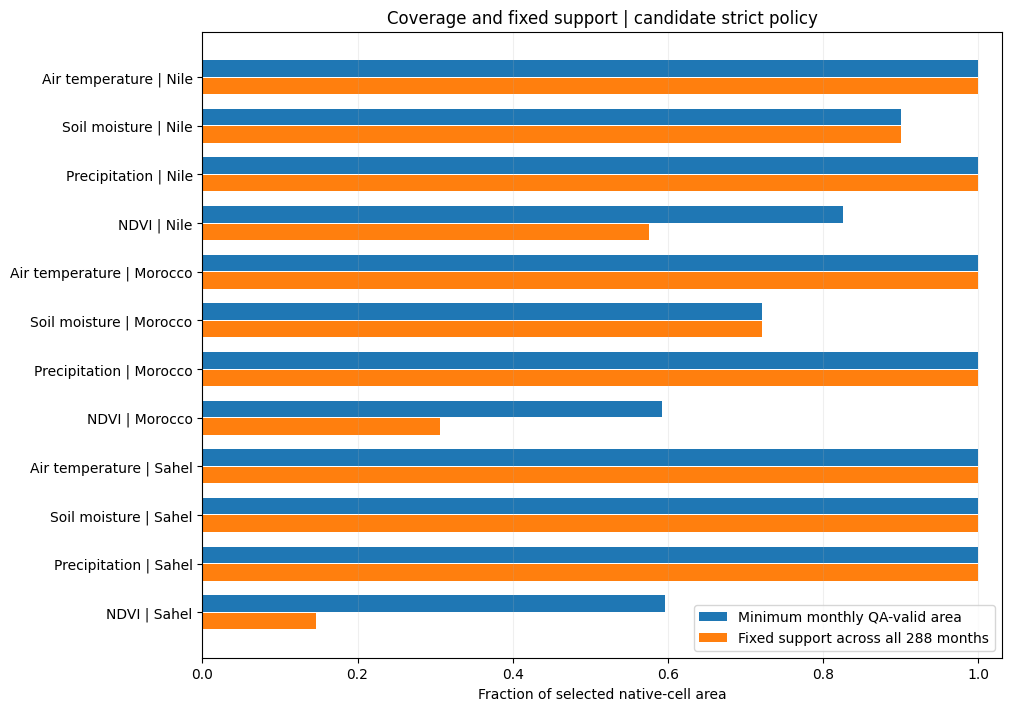

In [2]:
entries = report["entries"]
y = np.arange(len(entries))
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.barh(y - 0.18, [e["qa_valid_area_fraction_reference_min"] for e in entries], height=0.34, label="Minimum monthly QA-valid area")
ax.barh(y + 0.18, [e["fixed_support_area_fraction_of_selected_native_cells"] for e in entries], height=0.34, label="Fixed support across all 288 months")
ax.set_yticks(y, [f"{labels[e['variable_id']]} | {region_labels[e['region_id']]}" for e in entries])
ax.invert_yaxis()
ax.set_xlim(0, 1.03)
ax.set_xlabel("Fraction of selected native-cell area")
ax.set_title("Coverage and fixed support | candidate strict policy")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
fig.savefig(output / "coverage_summary.png", dpi=140)
display(fig)
plt.close(fig)

Coverage changes are explicit. The regional series uses the fixed subset, not a changing set of available cells. The subset can be geographically unrepresentative. Fractions below refer to selected native-cell area; the bbox selects cell centres, with full-cell spherical weights and no exact polygon intersection.

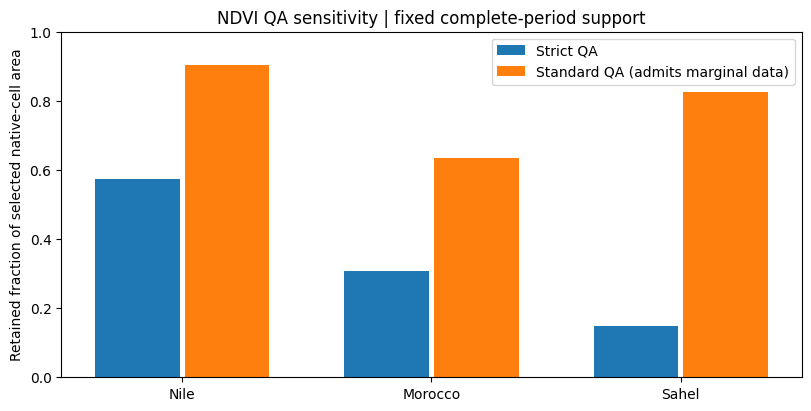

In [3]:
strict = {e["region_id"]:e for e in entries if e["variable_id"] == "vegetation_greenness"}
standard = {e["region_id"]:e for e in comparison["entries"]}
regions = list(strict)
x = np.arange(len(regions))
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.bar(x - 0.18, [strict[r]["fixed_support_area_fraction_of_selected_native_cells"] for r in regions], width=0.34, label="Strict QA")
ax.bar(x + 0.18, [standard[r]["fixed_support_area_fraction_of_selected_native_cells"] for r in regions], width=0.34, label="Standard QA (admits marginal data)")
ax.set_xticks(x, [region_labels[r] for r in regions])
ax.set_ylim(0, 1)
ax.set_ylabel("Retained fraction of selected native-cell area")
ax.set_title("NDVI QA sensitivity | fixed complete-period support")
ax.legend()
fig.savefig(output / "qa_sensitivity.png", dpi=140)
display(fig)
plt.close(fig)

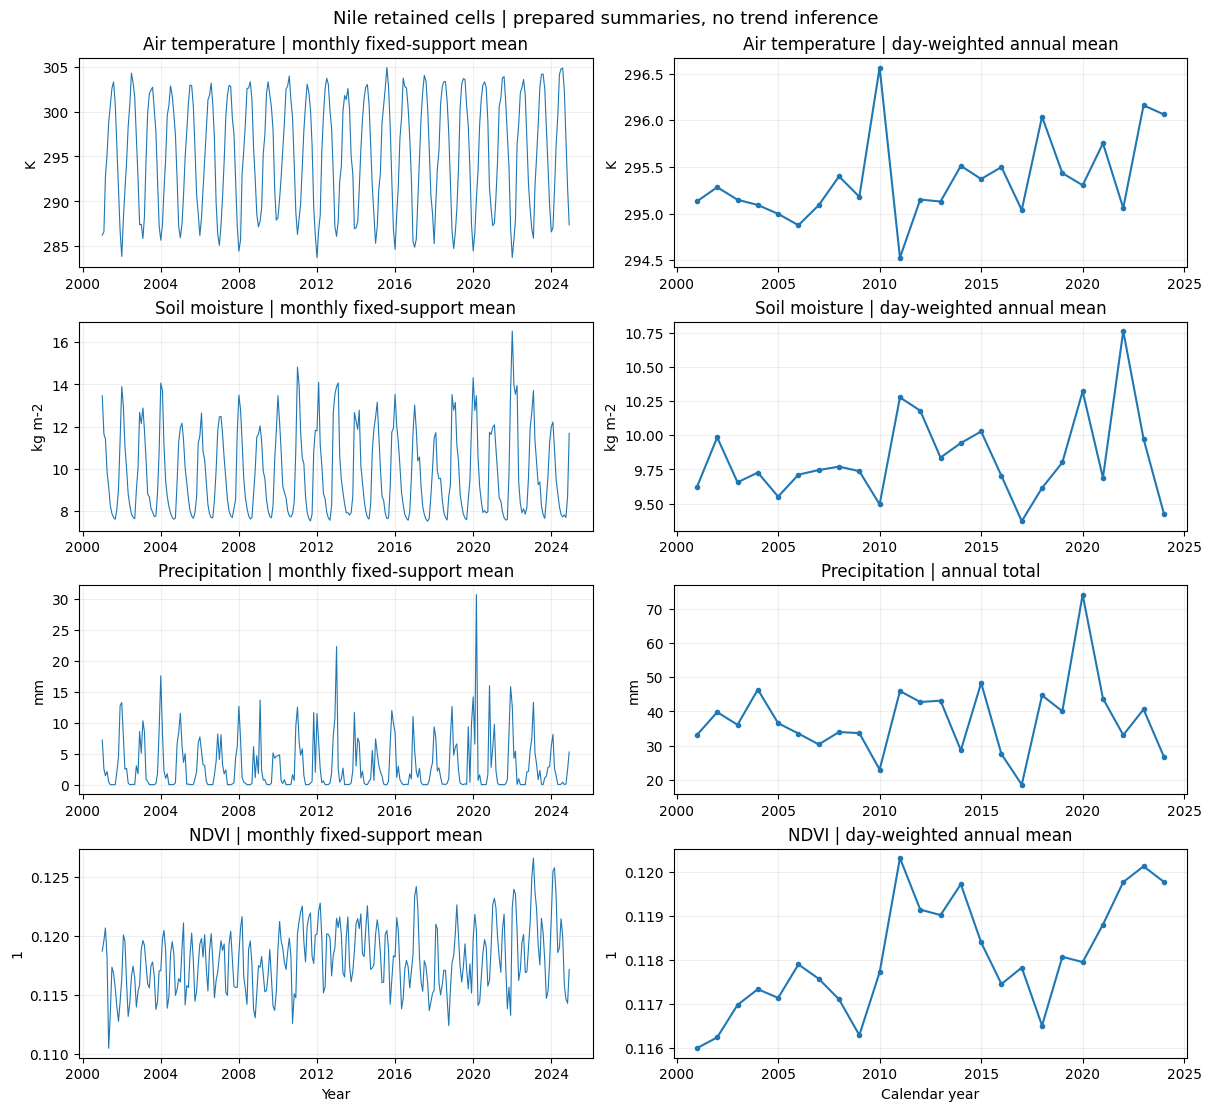

In [4]:
nile = [e for e in entries if e["region_id"] == "nile_corridor"]
fig, axes = plt.subplots(4, 2, figsize=(12, 11), layout="constrained")
for row, entry in enumerate(nile):
    with xr.open_dataset(root / entry["artifact"]) as ds:
        axes[row, 0].plot(ds.time.values, ds.regional_monthly.values, linewidth=0.8)
        axes[row, 1].plot(ds.year.values, ds.regional_annual.values, marker="o", markersize=3)
    axes[row, 0].set_title(f"{labels[entry['variable_id']]} | monthly fixed-support mean")
    annual_label = "annual total" if entry["variable_id"] == "precipitation" else "day-weighted annual mean"
    axes[row, 1].set_title(f"{labels[entry['variable_id']]} | {annual_label}")
    for col in range(2):
        axes[row, col].set_ylabel(entry["monthly_units"])
        axes[row, col].grid(alpha=0.2)
axes[-1, 0].set_xlabel("Year")
axes[-1, 1].set_xlabel("Calendar year")
fig.suptitle("Nile retained cells | prepared summaries, no trend inference", fontsize=13)
fig.savefig(output / "nile_prepared_series.png", dpi=140)
display(fig)
plt.close(fig)

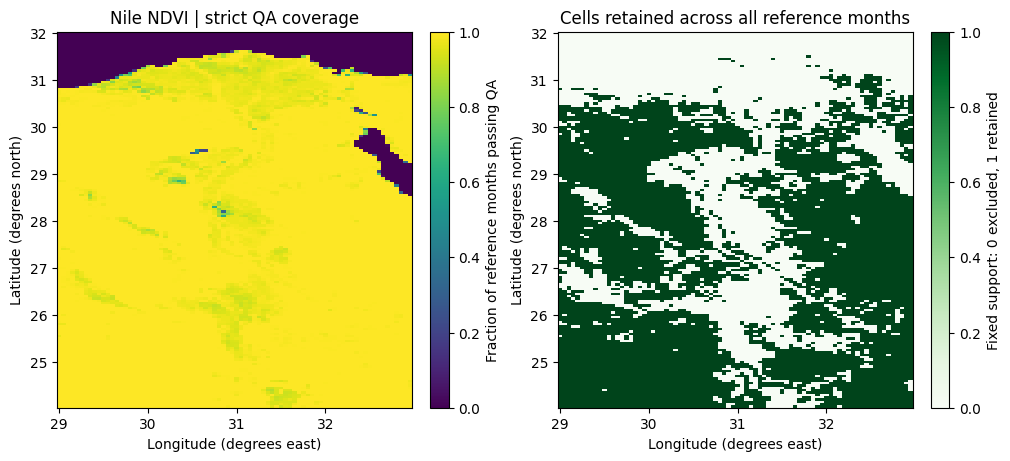

In [5]:
entry = strict["nile_corridor"]
with xr.open_dataset(root / entry["artifact"]) as ds:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
    ds.qa_valid_fraction_by_cell.plot(ax=axes[0], x="lon", y="lat", vmin=0, vmax=1, cmap="viridis", cbar_kwargs={"label":"Fraction of reference months passing QA"})
    ds.fixed_support.plot(ax=axes[1], x="lon", y="lat", vmin=0, vmax=1, cmap="Greens", cbar_kwargs={"label":"Fixed support: 0 excluded, 1 retained"})
    axes[0].set_title("Nile NDVI | strict QA coverage")
    axes[1].set_title("Cells retained across all reference months")
    for ax in axes:
        ax.set_xlabel("Longitude (degrees east)")
        ax.set_ylabel("Latitude (degrees north)")
    fig.savefig(output / "nile_ndvi_support.png", dpi=140)
    display(fig)
    plt.close(fig)

## What is and is not ready

Prepared files retain source ancillary fields, masked monthly values, a fixed-support cell mask, normalized spherical weights, calendar-month anomalies against the full registered reference, and annual summaries. Precipitation source rates are retained separately from monthly amounts. Incomplete years are missing, never scaled up or filled.

The strict-versus-standard comparison is a preparation sensitivity analysis. It is not uncertainty calibration or evidence of a trend. The owner must review the candidate QA/support policy and its spatial exclusions before downstream use. Inference and application readiness flags remain unchanged.